# Phase 6 Checks: Game Model and Monte Carlo

Verifies `src/processing/late_game.py`, `src/models/game_model.py`, `src/models/stochastic/montecarlo.py`
and `src/analysis/aggregation.py`. Needs the saved Track B fit (`fit_hierarchical.py`) and
`output/models/late_game.json` (`py -m src.processing.late_game`).

**Sections**
1. Setup
2. Late-game parameters
3. Exact vs Monte Carlo on many matchups
4. Reproducing history: how games ended *(the most important check)*
5. Reproducing history: final scores and empty-net goals
6. Calibration preview (in-sample)
7. Uncertainty: how wide are the intervals?
8. Sanity: home ice, goalies, mismatches

Each check prints **PASS** or **CHECK**. A CHECK isn't always a bug; read the note next to it.

**In-sample warning.** Sections 4-6 run the model on the same 2024-26 games Track B was fit on, so they test
whether the game model *reproduces* the data, not whether it *predicts* new games. Honest prediction tests are Phase 7.

## 1. Setup

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import sys; sys.path.insert(0, "..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from config.settings import OUTPUT_DIR
from src.data.db import get_connection
from src.processing.game_table import build_game_table
from src.processing.late_game import load_params, game_results
from src.models.stochastic.hierarchical import FIT_SEASONS
from src.models.game_model import (load_track_b, matchup_rates, outcome_probs, regulation_table,
                                   final_score_table, predict_matchup)
from src.models.stochastic.montecarlo import simulate_games, simulate_matchup, summarize_sims
from src.analysis.aggregation import format_prediction, fair_american_odds

def check(label, ok, note=""):
    print(f"{'PASS ' if ok else 'CHECK'}  {label}" + (f"   ({note})" if note else ""))

seasons = sorted(FIT_SEASONS)
FIT_PATH = OUTPUT_DIR / "posteriors" / f"hier_{seasons[0]}_{seasons[-1]}.nc"
draws, teams = load_track_b(FIT_PATH)
late = load_params(OUTPUT_DIR / "models" / "late_game.json")

conn = get_connection()
gt, gt_teams = build_game_table(conn, seasons)
results = game_results(conn, gt)
check("game table teams match the fit", gt_teams == teams)
print(f"games: {len(gt):,}   posterior draws: {draws['alpha0'].size:,}   teams: {len(teams)}")

PASS   game table teams match the fit
games: 2,624   posterior draws: 4,000   teams: 32


## 2. Late-game parameters

In [2]:
ot, so, en = late["ot"], late["shootout"], late["empty_net"]
print(f"OT factor {ot['ot_factor']:.2f} (90% {ot['ot_factor_90'][0]:.2f}-{ot['ot_factor_90'][1]:.2f})")
print(f"shootout home share {so['home_share']:.1%} -> using {so['use_home_prob']:.2f}")
for m, row in en["by_margin"].items():
    print(f"empty-net goals by leader, margin {m}: " + " / ".join(f"{p:.1%}" for p in row["probs"]))

check("fitted OT share matches the actual OT share (within 1 point)",
      abs(ot["share_decided_in_ot_fitted"] - ot["share_decided_in_ot"]) < 0.01,
      f"{ot['share_decided_in_ot_fitted']:.1%} vs {ot['share_decided_in_ot']:.1%}")
check("OT factor plausible (1.5-3.5: 3-on-3 scores faster than 5-on-5)", 1.5 < ot["ot_factor"] < 3.5)
check("home share of OT goals matches the ratings (within 4 points)",
      abs(ot["ot_home_share"] - ot["ot_home_share_expected"]) < 0.04,
      f"{ot['ot_home_share']:.1%} vs {ot['ot_home_share_expected']:.1%}")
check("empty-net probabilities sum to 1 for every margin",
      all(abs(sum(r["probs"]) - 1) < 1e-9 for r in en["by_margin"].values()))

OT factor 2.39 (90% 2.20-2.61)
shootout home share 49.5% -> using 0.50
empty-net goals by leader, margin 1: 51.0% / 40.9% / 8.1%
empty-net goals by leader, margin 2: 29.5% / 68.7% / 1.8%
empty-net goals by leader, margin 3: 79.1% / 20.9% / 0.0%
PASS   fitted OT share matches the actual OT share (within 1 point)   (67.1% vs 67.2%)
PASS   OT factor plausible (1.5-3.5: 3-on-3 scores faster than 5-on-5)
PASS   home share of OT goals matches the ratings (within 4 points)   (52.1% vs 51.9%)
PASS   empty-net probabilities sum to 1 for every margin


## 3. Exact vs Monte Carlo on many matchups

20 random matchups, each computed exactly (`game_model`) and simulated 50,000 times (`montecarlo`).
Every difference should be within simulation noise (4 standard errors).

In [3]:
rng = np.random.default_rng(0)
N_SIMS = 50_000
rows, worst_z = [], 0.0
for i in range(20):
    h, a = rng.choice(len(teams), 2, replace=False)
    gh, ga = rng.normal(0, 0.03, 2)
    ex = predict_matchup(draws, teams, late, teams[h], teams[a], gh, ga)
    sm = summarize_sims(simulate_matchup(draws, teams, late, teams[h], teams[a], gh, ga, n_sims=N_SIMS, seed=i))
    for key in ["home_win", "reg_home", "tie_reg", "ot_home", "so_home"]:
        p = ex["summary"][key]["mean"]
        z = abs(sm[key] - p) / np.sqrt(p * (1 - p) / N_SIMS)
        worst_z = max(worst_z, z)
    rows.append({"matchup": f"{teams[a]} @ {teams[h]}", "exact home win": ex["summary"]["home_win"]["mean"],
                 "simulated": sm["home_win"]})
    if i == 0:
        F = ex["final"]["table"]
        check("final-score table sums to 1", abs(F.sum() - 1) < 1e-4, f"{F.sum():.6f}")
        check("no ties in final scores (every game has a winner)", np.trace(F) < 1e-12)
        check("home win from final scores = exact home win",
              abs(np.tril(F, -1).sum() - ex["summary"]["home_win"]["mean"]) < 1e-6)
        p = ex["probs"]
        check("outcome probabilities sum to 1 for every draw",
              np.allclose(p["home_win"] + p["away_win"], 1, atol=1e-4))

display(pd.DataFrame(rows).round(4))
check("exact and simulated agree on all 5 outcomes x 20 matchups (|z| < 4)", worst_z < 4, f"worst |z| = {worst_z:.2f}")

PASS   final-score table sums to 1   (1.000000)
PASS   no ties in final scores (every game has a winner)
PASS   home win from final scores = exact home win
PASS   outcome probabilities sum to 1 for every draw


,matchup,exact home win,simulated
0,PHI @ TOR,0.5594,0.5580
1,CGY @ DAL,0.6133,0.6121
2,SJS @ WPG,0.6316,0.6308
3,NSH @ PIT,0.5532,0.5512
4,WSH @ SJS,0.4106,0.4130
5,CGY @ BUF,0.6074,0.6074
6,ANA @ CAR,0.6164,0.6174
7,PHI @ STL,0.5601,0.5608
8,PIT @ FLA,0.5328,0.5365
9,PHI @ VAN,0.4999,0.4996


PASS   exact and simulated agree on all 5 outcomes x 20 matchups (|z| < 4)   (worst |z| = 3.10)


## 4. Reproducing history: how games ended

Every 2024-26 game is run through the model with its real teams, home ice and starting goalies, using 400
posterior draws. Adding up the per-game probabilities gives the expected number of home wins, OT games and
shootouts; the 90% range comes from simulating outcomes from those probabilities.

In [4]:
N_DRAWS = 400
sub = np.random.default_rng(1).choice(draws["alpha0"].size, N_DRAWS, replace=False)
d = {k: v[sub] for k, v in draws.items()}

keys = ["home_win", "reg_home", "reg_away", "tie_reg", "ot_home", "ot_away", "so_home", "so_away"]
per_game = {k: np.zeros(len(gt)) for k in keys}
per_game_lo = np.zeros(len(gt)); per_game_hi = np.zeros(len(gt))
hi_, ai_ = gt.home_idx.to_numpy(), gt.away_idx.to_numpy()
CHUNK = 100
for start in range(0, len(gt), CHUNK):
    sl = slice(start, start + CHUNK)
    lam_h = np.exp(d["alpha0"][:, None] + d["alpha_home"][:, None] + d["mu_off"][:, hi_[sl]]
                   - d["mu_def"][:, ai_[sl]] - gt.gamma_away.to_numpy()[sl])
    lam_a = np.exp(d["alpha0"][:, None] + d["mu_off"][:, ai_[sl]] - d["mu_def"][:, hi_[sl]]
                   - gt.gamma_home.to_numpy()[sl])
    rho = np.repeat(d["rho"][:, None], lam_h.shape[1], axis=1)
    pr = outcome_probs(lam_h.ravel(), lam_a.ravel(), rho.ravel(), late)
    for k in keys:
        per_game[k][sl] = pr[k].reshape(lam_h.shape).mean(axis=0)
    hw = pr["home_win"].reshape(lam_h.shape)
    per_game_lo[sl], per_game_hi[sl] = np.quantile(hw, [0.05, 0.95], axis=0)

pred = pd.DataFrame(per_game).assign(game_id=gt.game_id.to_numpy(), hw_lo=per_game_lo, hw_hi=per_game_hi)
pred = pred.merge(results.rename(columns={"ot_home": "ot_home_actual", "so_home": "so_home_actual"}), on="game_id")

# Actual vs expected, with a 90% range from simulating outcomes game by game
r = np.random.default_rng(2)
cats = ["reg_home", "reg_away", "ot_home", "ot_away", "so_home", "so_away"]
P = pred[cats].to_numpy(); P = P / P.sum(axis=1, keepdims=True)
cum = P.cumsum(axis=1)
sim_counts = np.zeros((1000, len(cats)))
for s in range(1000):
    pick = (r.random(len(pred))[:, None] > cum).sum(axis=1)
    sim_counts[s] = np.bincount(pick, minlength=len(cats))
sim_shares = sim_counts / len(pred)

actual = {
    "reg_home": ((pred.decided == "REG") & (pred.home_won == 1)).mean(),
    "reg_away": ((pred.decided == "REG") & (pred.home_won == 0)).mean(),
    "ot_home": ((pred.decided == "OT") & (pred.home_won == 1)).mean(),
    "ot_away": ((pred.decided == "OT") & (pred.home_won == 0)).mean(),
    "so_home": ((pred.decided == "SO") & (pred.home_won == 1)).mean(),
    "so_away": ((pred.decided == "SO") & (pred.home_won == 0)).mean(),
}
groups = {"home win": ["reg_home", "ot_home", "so_home"], "decided in regulation": ["reg_home", "reg_away"],
          "decided in OT": ["ot_home", "ot_away"], "decided in shootout": ["so_home", "so_away"]}
rows = []
for name, cols in list(groups.items()) + [(c, [c]) for c in cats]:
    idx = [cats.index(c) for c in cols]
    sims = sim_shares[:, idx].sum(axis=1)
    act = sum(actual[c] for c in cols)
    lo, hi = np.quantile(sims, [0.05, 0.95])
    rows.append({"outcome": name, "actual": round(act, 4), "model expects": round(sims.mean(), 4),
                 "90% range": f"[{lo:.4f}, {hi:.4f}]", "inside": lo <= act <= hi})
hist = pd.DataFrame(rows)
display(hist)
for r_ in rows[:4]:
    note = ("a gap of about 1 point (regulation low, OT/shootout high) is the known empty-net 'hidden tie' effect"
            if r_["outcome"] != "home win" else "")
    check(f"{r_['outcome']}: actual inside the model's range", r_["inside"], note)

,outcome,actual,model expects,90% range,inside
0,home win,0.5423,0.5336,"[0.5175, 0.5503]",True
1,decided in regulation,0.7725,0.7632,"[0.7492, 0.7767]",True
2,decided in OT,0.1528,0.1587,"[0.1467, 0.1707]",True
3,decided in shootout,0.0747,0.0781,"[0.0697, 0.0869]",True
4,reg_home,0.4257,0.4123,"[0.3975, 0.4280]",True
5,reg_away,0.3468,0.3509,"[0.3354, 0.3662]",True
6,ot_home,0.0796,0.0822,"[0.0732, 0.0911]",True
7,ot_away,0.0732,0.0766,"[0.0682, 0.0854]",True
8,so_home,0.0370,0.0392,"[0.0332, 0.0454]",True
9,so_away,0.0377,0.0389,"[0.0328, 0.0457]",True


PASS   home win: actual inside the model's range
PASS   decided in regulation: actual inside the model's range   (a gap of about 1 point (regulation low, OT/shootout high) is the known empty-net 'hidden tie' effect)
PASS   decided in OT: actual inside the model's range   (a gap of about 1 point (regulation low, OT/shootout high) is the known empty-net 'hidden tie' effect)
PASS   decided in shootout: actual inside the model's range   (a gap of about 1 point (regulation low, OT/shootout high) is the known empty-net 'hidden tie' effect)


## 5. Reproducing history: final scores and empty-net goals

Every game simulated 20 times with random posterior draws (about 52,000 games), compared with the real
official final scores (empty-net goals and the OT/shootout +1 included).

mean final total: actual 6.167, simulated 6.160
empty-net share of regulation goals: actual 6.6%, simulated 6.3%
PASS   mean final total within 0.10 goals
PASS   empty-net share within 1 point
variance / mean of each team's final goals: actual 0.979, simulated 1.063
CHECK  final-score spread matches (variance / mean within 0.05)   (the empty-net step is what brings this back to Poisson-like)
one-goal games: actual 40.7%, simulated 38.1%
PASS   one-goal-game share within 3 points   (a gap here is the remaining score-effect item (v2.3))


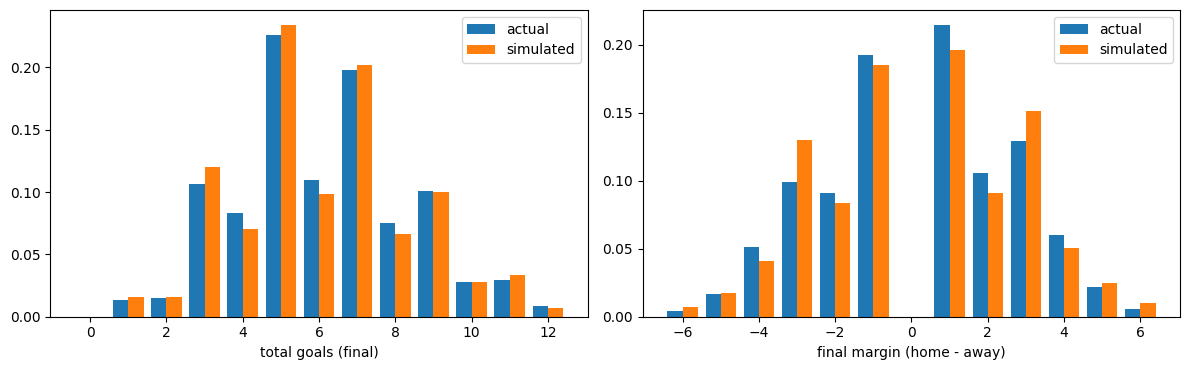

In [5]:
REPS = 20
rr = np.random.default_rng(3)
sims = simulate_games(draws, late, np.tile(hi_, REPS), np.tile(ai_, REPS),
                      np.tile(gt.gamma_home.to_numpy(), REPS), np.tile(gt.gamma_away.to_numpy(), REPS), rng=rr)

final = pd.read_sql("SELECT id AS game_id, home_score, away_score FROM games WHERE game_type = 2", conn)
act = gt[["game_id"]].merge(final, on="game_id")
act_total = (act.home_score + act.away_score).to_numpy()
act_margin = (act.home_score - act.away_score).to_numpy()
sim_total = (sims.final_home + sims.final_away).to_numpy()
sim_margin = (sims.final_home - sims.final_away).to_numpy()

act_en_share = (results.home_en.sum() + results.away_en.sum()) / (
    results.home_reg.sum() + results.away_reg.sum() + results.home_en.sum() + results.away_en.sum())
sm = summarize_sims(sims)
print(f"mean final total: actual {act_total.mean():.3f}, simulated {sim_total.mean():.3f}")
print(f"empty-net share of regulation goals: actual {act_en_share:.1%}, simulated {sm['en_share_of_goals']:.1%}")
check("mean final total within 0.10 goals", abs(act_total.mean() - sim_total.mean()) < 0.10)
check("empty-net share within 1 point", abs(act_en_share - sm["en_share_of_goals"]) < 0.01)

act_goals = np.concatenate([act.home_score, act.away_score])
sim_goals = np.concatenate([sims.final_home, sims.final_away])
vm_act, vm_sim = act_goals.var() / act_goals.mean(), sim_goals.var() / sim_goals.mean()
print(f"variance / mean of each team's final goals: actual {vm_act:.3f}, simulated {vm_sim:.3f}")
check("final-score spread matches (variance / mean within 0.05)", abs(vm_act - vm_sim) < 0.05,
      "the empty-net step is what brings this back to Poisson-like")
one_goal_act = (np.abs(act_margin) == 1).mean(); one_goal_sim = (np.abs(sim_margin) == 1).mean()
print(f"one-goal games: actual {one_goal_act:.1%}, simulated {one_goal_sim:.1%}")
check("one-goal-game share within 3 points", abs(one_goal_act - one_goal_sim) < 0.03,
      "a gap here is the remaining score-effect item (v2.3)")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
t = np.arange(0, 13)
axes[0].bar(t - 0.2, [(act_total == i).mean() for i in t], width=0.4, label="actual")
axes[0].bar(t + 0.2, [(sim_total == i).mean() for i in t], width=0.4, label="simulated")
axes[0].set_xlabel("total goals (final)"); axes[0].legend()
m = np.arange(-6, 7)
axes[1].bar(m - 0.2, [(act_margin == i).mean() for i in m], width=0.4, label="actual")
axes[1].bar(m + 0.2, [(sim_margin == i).mean() for i in m], width=0.4, label="simulated")
axes[1].set_xlabel("final margin (home - away)"); axes[1].legend()
plt.tight_layout()

## 6. Calibration preview (in-sample)

Games grouped by predicted home-win probability: in each group, did the home team win about as often as
predicted? Also log loss and Brier score against a "home team wins 54%" baseline. **In-sample, so optimistic**:
the ratings were fit on these games. The honest version is the Phase 7 walk-forward backtest.

log loss: model 0.6758   baseline 0.6896   (lower is better; coin flip 0.6931)
Brier:    model 0.2414   baseline 0.2482
predicted home-win range: 35.9% to 71.1%; picks the winner 57.3% of games
PASS   model beats the home-team baseline in-sample (log loss)


,predicted,actual,games,90% range
bin,,,,
"(0.358, 0.459]",0.432,0.373,263,0.050
"(0.459, 0.484]",0.473,0.492,262,0.051
"(0.484, 0.503]",0.494,0.462,262,0.051
"(0.503, 0.518]",0.510,0.517,263,0.051
"(0.518, 0.535]",0.527,0.527,262,0.051
"(0.535, 0.549]",0.542,0.538,262,0.051
"(0.549, 0.565]",0.557,0.567,263,0.050
"(0.565, 0.584]",0.574,0.569,262,0.050
"(0.584, 0.609]",0.596,0.691,262,0.050


PASS   calibration: most deciles inside their 90% range (at least 7 of 10)   (7/10)


Text(0.5, 1.0, 'Calibration (in-sample)')

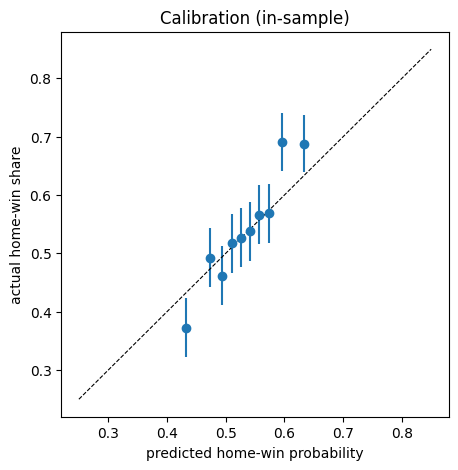

In [6]:
p = pred.home_win.clip(1e-6, 1 - 1e-6).to_numpy(); y = pred.home_won.to_numpy()
base = np.full_like(p, y.mean())
def log_loss(p, y): return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))
def brier(p, y): return np.mean((p - y) ** 2)
print(f"log loss: model {log_loss(p, y):.4f}   baseline {log_loss(base, y):.4f}   (lower is better; coin flip 0.6931)")
print(f"Brier:    model {brier(p, y):.4f}   baseline {brier(base, y):.4f}")
print(f"predicted home-win range: {p.min():.1%} to {p.max():.1%}; picks the winner {((p > 0.5) == y).mean():.1%} of games")
check("model beats the home-team baseline in-sample (log loss)", log_loss(p, y) < log_loss(base, y))

bins = pd.qcut(p, 10, duplicates="drop")
cal = pd.DataFrame({"p": p, "y": y, "bin": bins}).groupby("bin", observed=True).agg(
    predicted=("p", "mean"), actual=("y", "mean"), games=("y", "size"))
cal["90% range"] = 1.645 * np.sqrt(cal.predicted * (1 - cal.predicted) / cal.games)
display(cal.round(3))
inside = (abs(cal.actual - cal.predicted) <= cal["90% range"]).sum()
check("calibration: most deciles inside their 90% range (at least 7 of 10)", inside >= 7, f"{inside}/{len(cal)}")

fig, ax = plt.subplots(figsize=(5, 5))
ax.errorbar(cal.predicted, cal.actual, yerr=cal["90% range"], fmt="o")
ax.plot([0.25, 0.85], [0.25, 0.85], "k--", lw=0.8)
ax.set_xlabel("predicted home-win probability"); ax.set_ylabel("actual home-win share")
ax.set_title("Calibration (in-sample)")

## 7. Uncertainty: how wide are the intervals?

Each game's 90% interval on P(home win) comes from the spread of the rating posterior. Wide intervals mean the
model can't separate the teams well; Phase 7 checks whether those intervals are honest.

90% interval width on P(home win): median 11.9%, 10th-90th percentile 11.2%-12.7%
PASS   interval widths plausible (median 5-20 points)


Text(0.5, 0, 'width of 90% interval on P(home win)')

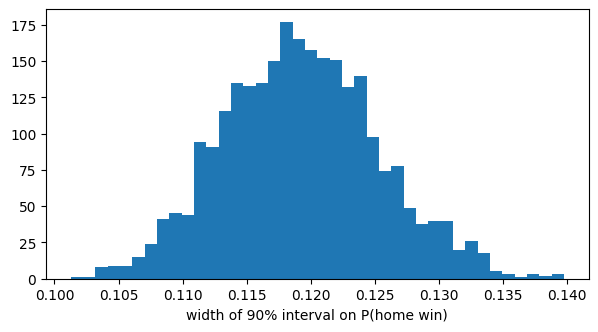

In [7]:
width = pred.hw_hi - pred.hw_lo
print(f"90% interval width on P(home win): median {width.median():.1%}, "
      f"10th-90th percentile {width.quantile(0.1):.1%}-{width.quantile(0.9):.1%}")
check("interval widths plausible (median 5-20 points)", 0.05 < width.median() < 0.20)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(width, bins=40); ax.set_xlabel("width of 90% interval on P(home win)")

## 8. Sanity: home ice, goalies, mismatches

In [8]:
order = list(pd.Series(draws["mu_off"].mean(0) + draws["mu_def"].mean(0), index=teams).sort_values().index)
best, worst, mid1, mid2 = order[-1], order[0], order[len(order) // 2], order[len(order) // 2 + 1]

def hw(home, away, gh=0.0, ga=0.0):
    return predict_matchup(draws, teams, late, home, away, gh, ga)["summary"]["home_win"]["mean"]

p_ab, p_ba = hw(mid1, mid2), hw(mid2, mid1)
home_edge = (p_ab + p_ba) / 2 - 0.5
print(f"home edge for two average teams: +{home_edge:.1%} (both orders averaged)")
check("home ice is worth 2-6 points of win probability", 0.02 < home_edge < 0.06)

p_best_home, p_best_away = hw(best, worst), 1 - hw(worst, best)
print(f"{best} vs {worst}: {p_best_home:.1%} at home, {p_best_away:.1%} away")
check("best team beats worst team most of the time (60-85%)", 0.60 < p_best_away < p_best_home < 0.85)

p_good_goalie = hw(mid1, mid2, gh=0.04)
p_bad_goalie = hw(mid1, mid2, gh=-0.04)
print(f"{mid1} at home with a +0.04 goalie: {p_good_goalie:.1%}; with a -0.04 goalie: {p_bad_goalie:.1%}")
check("a better home goalie raises the home win probability", p_good_goalie > p_ab > p_bad_goalie,
      f"swing {p_good_goalie - p_bad_goalie:.1%} for ±0.04")

print()
print(format_prediction(predict_matchup(draws, teams, late, best, worst), {"note": "best vs worst, league-average goalies"}))

home edge for two average teams: +3.3% (both orders averaged)
PASS   home ice is worth 2-6 points of win probability
COL vs SJS: 69.3% at home, 63.2% away
PASS   best team beats worst team most of the time (60-85%)
MTL at home with a +0.04 goalie: 55.1%; with a -0.04 goalie: 51.4%
PASS   a better home goalie raises the home win probability   (swing 3.7% for ±0.04)

SJS @ COL
  note: best vs worst, league-average goalies

COL win probability 69.3% (90% interval 63.3% - 75.3%)   fair odds COL -226 / SJS +226
The interval is how unsure the model is about the two teams' strength; game-to-game luck is already inside the probability.

Expected final score: COL 3.90 - 2.57 SJS (regulation rates 3.60 - 2.35)

How the game ends:
               outcome probability  90% interval fair odds
              COL wins       69.3% 63.3% - 75.3%      -226
              SJS wins       30.7% 24.7% - 36.7%      +226
COL wins in regulation       57.5% 50.9% - 64.1%          
        COL wins in OT        8.7%